<a href="https://colab.research.google.com/github/ascot119-rgb/Alex-s-Projects/blob/main/Basic_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Housing Dataset: Neural Network, Conventional Linreg, SVR

Epoch 1, Training loss 1.0502, Validation loss 0.8871
Epoch 2, Training loss 1.0419, Validation loss 0.8812
Epoch 3, Training loss 1.0338, Validation loss 0.8753
Epoch 4, Training loss 1.0259, Validation loss 0.8696
Epoch 5, Training loss 1.0180, Validation loss 0.8640
Epoch 6, Training loss 1.0103, Validation loss 0.8585
Epoch 7, Training loss 1.0028, Validation loss 0.8531
Epoch 8, Training loss 0.9953, Validation loss 0.8477
Epoch 9, Training loss 0.9879, Validation loss 0.8424
Epoch 10, Training loss 0.9806, Validation loss 0.8372
Epoch 20, Training loss 0.9110, Validation loss 0.7875
Epoch 30, Training loss 0.8448, Validation loss 0.7399
Epoch 40, Training loss 0.7803, Validation loss 0.6930
Epoch 50, Training loss 0.7177, Validation loss 0.6472
Epoch 60, Training loss 0.6586, Validation loss 0.6038
Epoch 70, Training loss 0.6050, Validation loss 0.5645
Epoch 80, Training loss 0.5581, Validation loss 0.5305
Epoch 90, Training loss 0.5186, Validation loss 0.5027
Epoch 100, Training

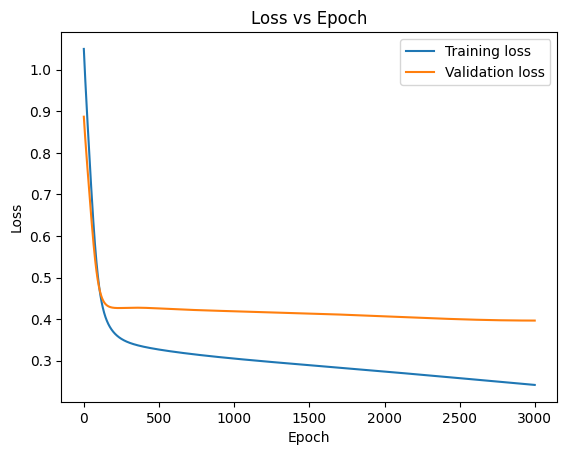

Validation loss MSE:  0.39657431840896606
Validation loss RMSE:  0.6297414695007516
Validation loss R^2:  0.5448879
0.weight torch.Size([10, 12])
0.bias torch.Size([10])
2.weight torch.Size([5, 10])
2.bias torch.Size([5])
4.weight torch.Size([1, 5])
4.bias torch.Size([1])


In [120]:
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle

filepath = "/content/Housing.csv"

df = pd.read_csv(filepath)

scaler_X = StandardScaler() # Scaler for input features
scaler_y = StandardScaler() # Scaler for target variable

t_u = df.values[:, 1:13]
t_c = df.values[:, 0].astype(np.float32)

t_u, t_c = shuffle(t_u, t_c)

for i in range(len(t_u)):
  for j in range(len(t_u[0])):
    if t_u[i][j] == "yes":
      t_u[i][j] = 1
    elif t_u[i][j] == "no":
      t_u[i][j] = 0
for i in range(len(t_u)):
  if t_u[i][11] == "furnished":
    t_u[i][11] = 2
  elif t_u[i][11] == "semi-furnished":
    t_u[i][11] = 1
  elif t_u[i][11] == "unfurnished":
    t_u[i][11] = 0

t_u = t_u.astype(np.float32)

validation_indices = np.arange(0, len(t_u), 5)

t_uv = t_u[validation_indices]
t_u = np.delete(t_u, validation_indices, axis=0)

t_u = scaler_X.fit_transform(t_u) # Fit and transform input features
t_uv = scaler_X.transform(t_uv)

t_c = scaler_y.fit_transform(t_c.reshape(-1, 1)).reshape(-1) # Fit and transform target variable

t_cv = t_c[validation_indices]
t_c = np.delete(t_c, validation_indices)

t_c = pt.from_numpy(t_c)
t_cv = pt.from_numpy(t_cv)
t_c = pt.unsqueeze(t_c, 1)
t_cv = pt.unsqueeze(t_cv, 1)
t_u = pt.from_numpy(t_u)
t_uv = pt.from_numpy(t_uv)

def r_2(y_true, y_pred):
  mean = np.mean(y_true)
  mean_diff = np.sum((y_true - mean) ** 2)
  pred_diff = np.sum((y_true - y_pred) ** 2)
  return 1 - (pred_diff / mean_diff)

def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
  t_l_time = []
  v_l_time = []
  for epoch in range(1, n_epochs + 1):
    t_p_train = model(t_u_train)
    loss_train = loss_fn(t_p_train, t_c_train)
    t_l_time.append(loss_train.item())

    t_p_val = model(t_u_val)
    loss_val = loss_fn(t_p_val, t_c_val)
    v_l_time.append(loss_val.item())

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    if (epoch < 10) or (epoch < 100 and epoch % 10 == 0) or (epoch < 1000 and epoch % 100 == 0) or (epoch % 1000 == 0):
      print(f"Epoch {epoch}, Training loss {loss_train.item():.4f}, Validation loss {loss_val.item():.4f}")

  # Printing Results
  plt.plot(np.arange(len(t_l_time)), t_l_time, label="Training loss")
  plt.plot(np.arange(len(v_l_time)), v_l_time, label="Validation loss")
  plt.title("Loss vs Epoch")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()
  print("Validation loss MSE: ", loss_val.item())
  print("Validation loss RMSE: ", np.sqrt(loss_val.item()))
  print("Validation loss R^2: ", r_2(t_c_val.detach().numpy(), t_p_val.detach().numpy()))


def train(s1, s2, t_u, t_c, t_uv, t_cv, lr=0.01):
  model = nn.Sequential(
      nn.Linear(len(t_u[0]), s1),
      nn.ReLU(),
      nn.Linear(s1, s2),
      nn.ReLU(),
      nn.Linear(s2, 1)
  )
  optimizer = pt.optim.SGD(model.parameters(), lr=lr)

  training_loop(
    n_epochs = 3000,
    optimizer = optimizer,
    model = model,
    loss_fn = nn.MSELoss(),
    t_u_train = t_u,
    t_u_val = t_uv,
    t_c_train = t_c,
    t_c_val = t_cv
  )

  for name, param in model.named_parameters():
    print(name, param.shape)


train(10, 5, t_u, t_c, t_uv, t_cv, 0.01)







Iterations: 0
Parameters: 
0.010464x1 + 0.008278x2 + 0.010037x3 + 0.009075x4 + 0.006354x5 + 0.005818x6 + 0.003986x7 + 0.002420x8 + 0.009037x9 + 0.007938x10 + 0.005808x11 + 0.006620x12 + 0.000377
Cost: 0.981676
Iterations: 100
Parameters: 
0.229725x1 + 0.104687x2 + 0.221409x3 + 0.199819x4 + 0.102326x5 + 0.091093x6 + 0.087378x7 + 0.090364x8 + 0.196718x9 + 0.135636x10 + 0.119973x11 + 0.120768x12 + -0.000055
Cost: 0.303319
Iterations: 200
Parameters: 
0.243104x1 + 0.075752x2 + 0.233947x3 + 0.215741x4 + 0.093268x5 + 0.081892x6 + 0.098455x7 + 0.102076x8 + 0.204508x9 + 0.129033x10 + 0.124041x11 + 0.119380x12 + -0.002276
Cost: 0.301104
Iterations: 300
Parameters: 
0.247458x1 + 0.064428x2 + 0.237662x3 + 0.223220x4 + 0.089672x5 + 0.078128x6 + 0.104140x7 + 0.104011x8 + 0.205199x9 + 0.127150x10 + 0.124685x11 + 0.119076x12 + -0.002763
Cost: 0.300794


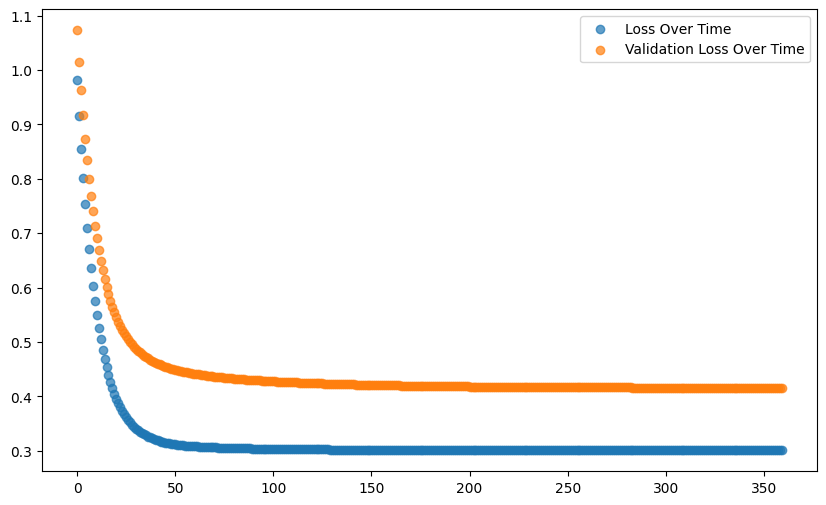

Iterations: 360
Parameters: 
0.248634x1 + 0.061328x2 + 0.238500x3 + 0.225657x4 + 0.088674x5 + 0.077047x6 + 0.105992x7 + 0.104242x8 + 0.205005x9 + 0.126815x10 + 0.124710x11 + 0.119052x12 + -0.002854
Cost: 0.300753
MSE Cost: 0.415715
RMSE Cost: 0.644760
R^2 Score: 0.610608


In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
def find(l, t):
  for i in range(len(l)):
    if l[i] == t:
      return i
  return -1
filepath = "/content/Housing.csv"

df = pd.read_csv(filepath)

scaler_X = StandardScaler() # Scaler for input features
scaler_y = StandardScaler() # Scaler for target variable

inputdata = df.values[:, 1:13]
y = df.values[:, 0].astype(np.float32)

y, inputdata = shuffle(y, inputdata)

for i in range(len(inputdata)):
  for j in range(len(inputdata[0])):
    if inputdata[i][j] == "yes":
      inputdata[i][j] = 1
    elif inputdata[i][j] == "no":
      inputdata[i][j] = 0
for i in range(len(inputdata)):
  if inputdata[i][11] == "furnished":
    inputdata[i][11] = 2
  elif inputdata[i][11] == "semi-furnished":
    inputdata[i][11] = 1
  elif inputdata[i][11] == "unfurnished":
    inputdata[i][11] = 0

params = np.zeros(len(inputdata[0]) + 1)

inputdata = inputdata.astype(np.float32).T

inputdata = np.array(inputdata).T
originaldata = inputdata.copy()
originaldata = np.array(originaldata).T
inputdata = scaler_X.fit_transform(inputdata) # Fit and transform input features

validation_indices = np.arange(0, len(inputdata), 5)
validationdata = inputdata[validation_indices]
inputdata = np.delete(inputdata, validation_indices, axis=0)

originaldata = originaldata.T
originaldata = np.delete(originaldata, validation_indices, axis=0)
originaldata = originaldata.T

inputdata = inputdata.T
validationdata = validationdata.T

index = np.arange(0, len(inputdata[0]))

y = scaler_y.fit_transform(y.reshape(-1, 1)).reshape(-1) # Fit and transform target variable

validationy = y[validation_indices]
y = np.delete(y, validation_indices)

m = len(y)

cf = 10
lr = 0.02

def r_2(y_true, y_pred):
  mean = np.mean(y_true)
  mean_diff = np.sum((y_true - mean) ** 2)
  pred_diff = np.sum((y_true - y_pred) ** 2)
  return 1 - (pred_diff / mean_diff)

def cost_function(res, y):
  for i in range(len(res)):
    res[i] = np.float64(res[i])
  for i in range(len(y)):
    y[i] = np.float64(y[i])
  return np.sum((res - y) ** 2) / (len(res))

def plot_result_to_target(result, y, x, loss, vloss):
  plt.figure(figsize=(10, 6))
  plt.scatter(range(len(loss)), loss, label='Loss Over Time', alpha=0.7)
  plt.scatter(range(len(vloss)), vloss, label='Validation Loss Over Time', alpha=0.7)
  plt.legend() # Add this line to display labels
  #for i in range(len(x)):
    #plt.scatter(index, x[i], label=f'Index vs X{i+1}', alpha=0.7)
  plt.show()

def gradient(result, y, x):
  temp = np.zeros(len(params))
  for ind in range(len(params) - 1):
    temp[ind] = np.float64(np.sum((result - y) * x[ind])) / m
  temp[len(params) - 1] = np.float64(np.sum(result - y)) / m
  return temp

def linearfun(data, params):
  ans = np.zeros(len(data[0]))
  for i in range(len(params) - 1):
    ans += list(params[i] * data[i])
  return ans + params[len(params) - 1]

def printdata(iter, cf, params):
  print(f"Iterations: {iter}")
  print(f"Parameters: ")
  for i in range (len(params) - 1):
    print(f"{params[i]:.6f}x{i+1} +", end = " ")
  print(f"{params[len(params) - 1]:.6f}")
  print(f"Cost: {cf:.6f}")


def linregression(data, params, y, origdata):
  # Early setup
  grad = [500] * len(params)
  iteration = 0
  loss_over_time = []
  validation_loss_over_time = []

  # Core Iteration
  while any(abs(x) > 0.002 for x in grad):
    result = linearfun(data, params)
    cf = cost_function(result, y)
    grad = gradient(result, y, data)
    loss_over_time.append(cf)
    validation_cf = cost_function(linearfun(validationdata, params), validationy)
    validation_loss_over_time.append(validation_cf)
    for i in range(len(params)):
      params[i] = params[i] - lr * grad[i]
    if iteration % 100 == 0:
      printdata(iteration, cf, params)
    iteration += 1

  final_prediction = linearfun(validationdata, params)
  validationcf = cost_function(final_prediction, validationy)


  # Plotting and displaying information
  plot_result_to_target(final_prediction, validationy, validationdata, loss_over_time, validation_loss_over_time)
  printdata(iteration, cf, params)
  print(f"MSE Cost: {(validationcf):.6f}")
  print(f"RMSE Cost: {validationcf**0.5:.6f}")
  print(f"R^2 Score: {r_2(validationy, final_prediction):.6f}")
  iteration = 0

linregression(inputdata, params, y, originaldata)

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random as rnd
from sklearn.preprocessing import StandardScaler
from sklearn import svm
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.utils import shuffle

def cost_function(res, y):
  return np.sum((res - y) ** 2) / (len(res))
def r_2_function(y_true, y_pred):
  mean = np.mean(y_true)
  mean_diff = np.sum((y_true - mean) ** 2)
  pred_diff = np.sum((y_true - y_pred) ** 2)
  return 1 - (pred_diff / mean_diff)

filepath = "/content/Housing.csv"

df = pd.read_csv(filepath)

scaler_X = StandardScaler() # Scaler for input features
scaler_Y = StandardScaler() # Scaler for output features

y = df.values[:, 0]

paramnames = df.columns.values[:]
params = np.zeros(len(df.values[0]))
inputdata = df.values[:, 1:]

inputdata, y = shuffle(inputdata, y)

for i in range(len(inputdata)):
  for j in range(len(inputdata[i])):
    if inputdata[i][j] == "yes":
      inputdata[i][j] = 1
    elif inputdata[i][j] == "no":
      inputdata[i][j] = 0
for i in range(len(inputdata)):
  if inputdata[i][11] == "furnished":
    inputdata[i][11] = 2
  elif inputdata[i][11] == "semi-furnished":
    inputdata[i][11] = 1
  elif inputdata[i][11] == "unfurnished":
    inputdata[i][11] = 0

inputdata = np.array(inputdata)
inputdata = scaler_X.fit_transform(inputdata) # Fit and transform input features

validation_indices = np.arange(rnd.randint(0, 4), len(inputdata), 5)
validationdata = inputdata[validation_indices]
inputdata = np.delete(inputdata, validation_indices, axis=0)

validationy = y[validation_indices]
y = np.delete(y, validation_indices)

y = np.array(y)
y = y.reshape(-1, 1)
y = scaler_Y.fit_transform(y) # Fit and transform input features
validationy = np.array(validationy)
validationy = validationy.reshape(-1, 1)
validationy = (scaler_Y.transform(validationy).T)[0]

result = svm.SVR(kernel="linear", epsilon=0.2).fit(inputdata, y.ravel())

final_y_values = (result.predict(validationdata))
final_cost = cost_function(final_y_values, validationy)
print("Final MSE Linear: ", final_cost)
print("Final RMSE Linear: ", np.sqrt(final_cost))
print("Final R2 Linear:" , r_2_function(validationy, final_y_values))

result = svm.SVR(kernel="poly", epsilon=0.2).fit(inputdata, y.ravel())

final_y_values = (result.predict(validationdata))
final_cost = cost_function(final_y_values, validationy)
print("Final MSE Poly: ", final_cost)
print("Final RMSE Poly: ", np.sqrt(final_cost))
print("Final R2 Poly:" , r_2_function(validationy, final_y_values))

result = svm.SVR(kernel="rbf", epsilon=0.2).fit(inputdata, y.ravel())

final_y_values = (result.predict(validationdata))
final_cost = cost_function(final_y_values, validationy)
print("Final MSE RBF: ", final_cost)
print("Final RMSE RBF: ", np.sqrt(final_cost))
print("Final R2 RBF:" , r_2_function(validationy, final_y_values))

result = svm.SVR(kernel="sigmoid", epsilon=0.2).fit(inputdata, y.ravel())

final_y_values = (result.predict(validationdata))
final_cost = cost_function(final_y_values, validationy)
print("Final MSE Sigmoid: ", final_cost)
print("Final RMSE Sigmoid: ", np.sqrt(final_cost))
print("Final R2 Sigmoid:" , r_2_function(validationy, final_y_values))

Final MSE Linear:  0.3519110216452154
Final RMSE Linear:  0.5932208877350961
Final R2 Linear: 0.5509829692305719
Final MSE Poly:  0.39677023830393876
Final RMSE Poly:  0.6298970061080928
Final R2 Poly: 0.4937453408875486
Final MSE RBF:  0.33601742666347534
Final RMSE RBF:  0.5796701015780229
Final R2 RBF: 0.5712622284410083
Final MSE Sigmoid:  1.3820459672294079
Final RMSE Sigmoid:  1.1756045114022862
Final R2 Sigmoid: -0.7634064818175561


Classifier

Epoch 1, Training loss 0.7439, Validation loss 0.7518
Epoch 2, Training loss 0.7425, Validation loss 0.7504
Epoch 3, Training loss 0.7412, Validation loss 0.7490
Epoch 4, Training loss 0.7399, Validation loss 0.7476
Epoch 5, Training loss 0.7385, Validation loss 0.7462
Epoch 6, Training loss 0.7372, Validation loss 0.7448
Epoch 7, Training loss 0.7360, Validation loss 0.7435
Epoch 8, Training loss 0.7347, Validation loss 0.7422
Epoch 9, Training loss 0.7334, Validation loss 0.7409
Epoch 10, Training loss 0.7322, Validation loss 0.7396
Epoch 20, Training loss 0.7204, Validation loss 0.7273
Epoch 30, Training loss 0.7097, Validation loss 0.7161
Epoch 40, Training loss 0.6997, Validation loss 0.7058
Epoch 50, Training loss 0.6903, Validation loss 0.6962
Epoch 60, Training loss 0.6812, Validation loss 0.6871
Epoch 70, Training loss 0.6723, Validation loss 0.6782
Epoch 80, Training loss 0.6636, Validation loss 0.6697
Epoch 90, Training loss 0.6549, Validation loss 0.6612
Epoch 100, Training

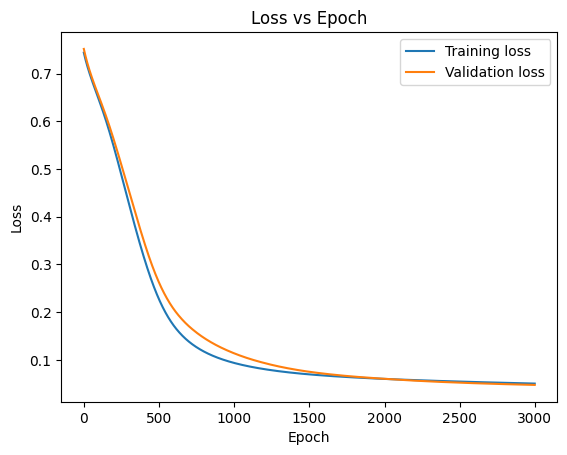

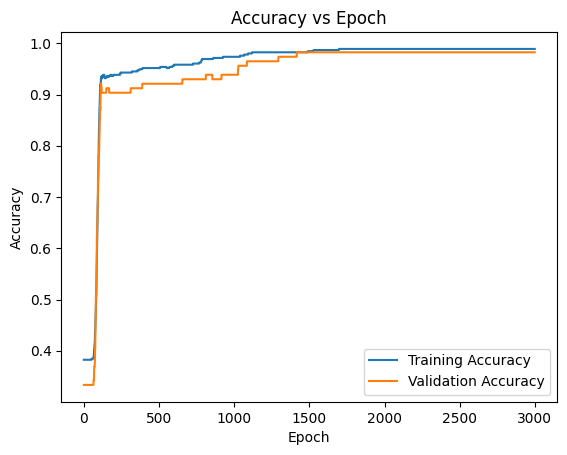

Accuracy:  0.9824561403508771
Precision:  0.9736842105263158
Recall:  0.9736842105263158
F1:  0.9736842105263158


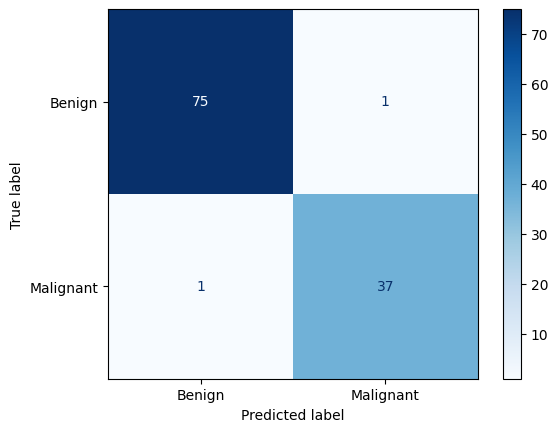

In [123]:
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import log_loss
from decimal import Decimal
from sklearn.utils.multiclass import type_of_target

filepath = "/content/Cancer.csv"

df = pd.read_csv(filepath)

scaler_X = StandardScaler() # Scaler for input features

t_u = df.values[:, 2:-1]
t_c = df.values[:, 1]

t_u, t_c = shuffle(t_u, t_c)

for i in range(len(t_u)):
  for j in range(len(t_u[0])):
    if t_u[i][j] == "yes":
      t_u[i][j] = 1
    elif t_u[i][j] == "no":
      t_u[i][j] = 0
for i in range(len(t_c)):
  if t_c[i] == "M":
    t_c[i] = 1
  else:
    t_c[i] = 0

t_u = t_u.astype(np.float32)
t_c = t_c.astype(np.float32)

validation_indices = np.arange(0, len(t_u), 5)

t_uv = t_u[validation_indices]
t_u = np.delete(t_u, validation_indices, axis=0)

t_u = scaler_X.fit_transform(t_u) # Fit and transform input features
t_uv = scaler_X.transform(t_uv)

t_cv = t_c[validation_indices]
t_c = np.delete(t_c, validation_indices)

t_c = pt.from_numpy(t_c)
t_cv = pt.from_numpy(t_cv)
t_c = pt.unsqueeze(t_c, 1)
t_cv = pt.unsqueeze(t_cv, 1)
t_u = pt.from_numpy(t_u)
t_uv = pt.from_numpy(t_uv)

def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)

def getprecision(predict, y):
  p = 0
  tp = 0
  for i in range(len(predict)):
    if predict[i] >= 0.5:
      p += 1
    if predict[i] >= 0.5 and y[i] == 1:
      tp += 1
  return tp/p

def getrecall(predict, y):
  rp = 0
  tp = 0
  for i in range(len(predict)):
    if y[i] == 1:
      rp += 1
    if predict[i] >= 0.5 and y[i] == 1:
      tp += 1
  return tp/rp
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
  t_l_time = []
  v_l_time = []
  t_a_time = []
  v_a_time = []
  for epoch in range(1, n_epochs + 1):
    t_p_train = model(t_u_train)
    loss_train = loss_fn(t_p_train, t_c_train)
    t_l_time.append(loss_train.item())
    t_a_time.append(getaccuracy(t_p_train.detach().numpy(), t_c_train.detach().numpy()))

    t_p_val = model(t_u_val)
    loss_val = loss_fn(t_p_val, t_c_val)
    v_l_time.append(loss_val.item())
    v_a_time.append(getaccuracy(t_p_val.detach().numpy(), t_c_val.detach().numpy()))

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    if (epoch < 10) or (epoch < 100 and epoch % 10 == 0) or (epoch < 1000 and epoch % 100 == 0) or (epoch % 1000 == 0):
      print(f"Epoch {epoch}, Training loss {loss_train.item():.4f}, Validation loss {loss_val.item():.4f}")

  # Printing Results
  plt.plot(np.arange(len(t_l_time)), t_l_time, label="Training loss")
  plt.plot(np.arange(len(v_l_time)), v_l_time, label="Validation loss")
  plt.title("Loss vs Epoch")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()
  plt.plot(np.arange(len(t_a_time)), t_a_time, label="Training Accuracy")
  plt.plot(np.arange(len(v_a_time)), v_a_time, label="Validation Accuracy")
  plt.title("Accuracy vs Epoch")
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()
  t_p_val = model(t_u_val)
  accuracy = getaccuracy(t_p_val.detach().numpy(), t_c_val.detach().numpy())
  recall = getrecall(t_p_val.detach().numpy(), t_c_val.detach().numpy())
  precision = getprecision(t_p_val.detach().numpy(), t_c_val.detach().numpy())
  f1 = getf1(precision, recall)
  print("Accuracy: ", accuracy)
  print("Precision: ", precision)
  print("Recall: ", recall)
  print("F1: ", f1)
  class_names = ["Benign", "Malignant"]

  disp = ConfusionMatrixDisplay.from_predictions(
        np.round(t_p_val.detach().numpy()),
        t_c_val.detach().numpy(),
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize=None,
  )


def train(s1, s2, t_u, t_c, t_uv, t_cv, lr=0.01):
  model = nn.Sequential(
      nn.Linear(len(t_u[0]), s1),
      nn.ReLU(),
      nn.Linear(s1, s2),
      nn.ReLU(),
      nn.Linear(s2, 1),
      nn.Sigmoid()
  )
  optimizer = pt.optim.SGD(model.parameters(), lr=lr)

  training_loop(
    n_epochs = 3000,
    optimizer = optimizer,
    model = model,
    loss_fn = nn.BCELoss(),
    t_u_train = t_u,
    t_u_val = t_uv,
    t_c_train = t_c,
    t_c_val = t_cv
  )



train(40, 26, t_u, t_c, t_uv, t_cv, 0.01)


Linear Kernel
Accuracy:  0.9736842105263158
Precision:  1.0
Recall:  0.925
F1 Score:  0.961038961038961
Polynomial Kernel
Accuracy:  0.8947368421052632
Precision:  1.0
Recall:  0.7
F1 Score:  0.8235294117647058
RBF Kernel
Accuracy:  0.9736842105263158
Precision:  0.9743589743589743
Recall:  0.95
F1 Score:  0.9620253164556962
Sigmoid Kernel
Accuracy:  0.9649122807017544
Precision:  0.95
Recall:  0.95
F1 Score:  0.9500000000000001


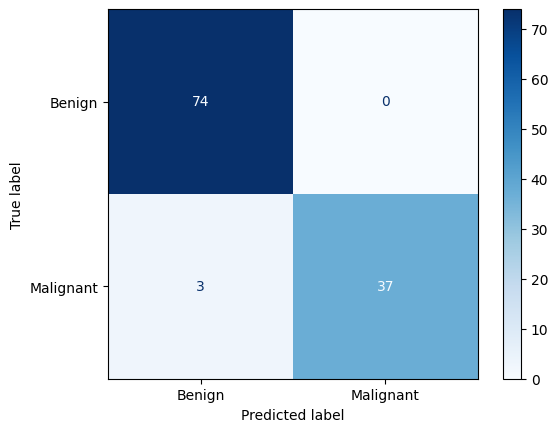

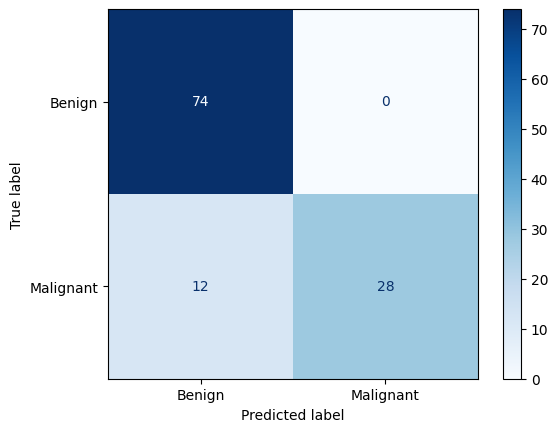

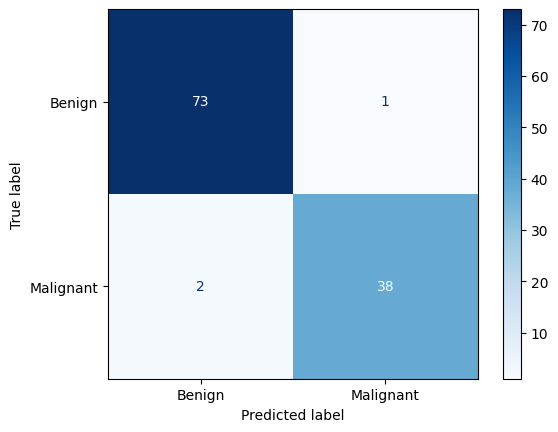

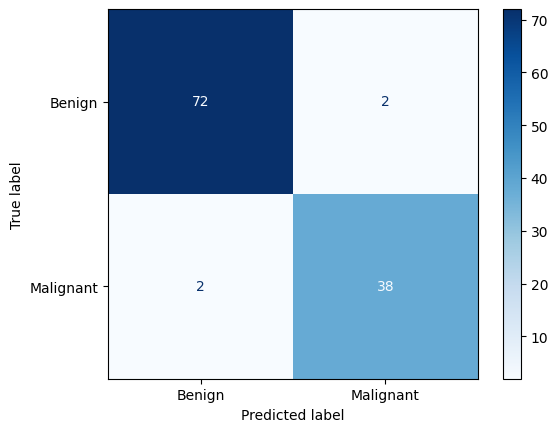

In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random as rnd
from sklearn.preprocessing import StandardScaler
from sklearn import svm
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.utils.multiclass import type_of_target

def getprecision(predict, y):
  p = 0
  tp = 0
  for i in range(len(predict)):
    if predict[i] == 1:
      p += 1
    if predict[i] == 1 and y[i] == 1:
      tp += 1
  return tp/p

def getrecall(predict, y):
  rp = 0
  tp = 0
  for i in range(len(predict)):
    if y[i] == 1:
      rp += 1
    if predict[i] == 1 and y[i] == 1:
      tp += 1
  return tp/rp
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

filepath = "/content/Cancer.csv"

df = pd.read_csv(filepath)

scaler_X = StandardScaler() # Scaler for input features


y = df.values[:, 1]
for i in range(len(y)):
  if y[i] == "M":
    y[i] = 1
  else:
    y[i] = 0
y=y.astype(int)

paramnames = df.columns.values[:]
params = np.zeros(len(df.values[0]))
inputdata = df.values[:, 2:-1]

inputdata, y = shuffle(inputdata, y)

inputdata = np.array(inputdata)
inputdata = scaler_X.fit_transform(inputdata) # Fit and transform input features


validation_indices = np.arange(0, len(inputdata), 5)
validationdata = inputdata[validation_indices]
inputdata = np.delete(inputdata, validation_indices, axis=0)

index = np.arange(0, len(inputdata))

validationy = y[validation_indices]
y = np.delete(y, validation_indices)

BOLD = '\033[1m'
END = '\033[0m'

result = svm.SVC(kernel="linear", C=1.0).fit(inputdata,y)
print(BOLD + "Linear Kernel" + END)
print("Accuracy: ", result.score(validationdata, validationy))
precision = getprecision(result.predict(validationdata), validationy)
recall = getrecall(result.predict(validationdata), validationy)
print("Precision: ", precision)
print("Recall: ", recall)
print("F1 Score: ", getf1(precision, recall))

class_names = ["Benign", "Malignant"]

disp = ConfusionMatrixDisplay.from_estimator(
      result,
      validationdata,
      validationy,
      display_labels=class_names,
      cmap=plt.cm.Blues,
      normalize=None,
 )

result = svm.SVC(kernel="poly", C=1.0).fit(inputdata,y)
print(BOLD + "Polynomial Kernel" + END)
print("Accuracy: ", result.score(validationdata, validationy))
precision = getprecision(result.predict(validationdata), validationy)
recall = getrecall(result.predict(validationdata), validationy)
print("Precision: ", precision)
print("Recall: ", recall)
print("F1 Score: ", getf1(precision, recall))

class_names = ["Benign", "Malignant"]

disp = ConfusionMatrixDisplay.from_estimator(
      result,
      validationdata,
      validationy,
      display_labels=class_names,
      cmap=plt.cm.Blues,
      normalize=None,
 )

result = svm.SVC(kernel="rbf", C=1.0).fit(inputdata,y)
print(BOLD + "RBF Kernel" + END)
print("Accuracy: ", result.score(validationdata, validationy))
precision = getprecision(result.predict(validationdata), validationy)
recall = getrecall(result.predict(validationdata), validationy)
print("Precision: ", precision)
print("Recall: ", recall)
print("F1 Score: ", getf1(precision, recall))

class_names = ["Benign", "Malignant"]

disp = ConfusionMatrixDisplay.from_estimator(
      result,
      validationdata,
      validationy,
      display_labels=class_names,
      cmap=plt.cm.Blues,
      normalize=None,
 )

result = svm.SVC(kernel="sigmoid", C=1.0).fit(inputdata,y)
print(BOLD + "Sigmoid Kernel" + END)
print("Accuracy: ", result.score(validationdata, validationy))
precision = getprecision(result.predict(validationdata), validationy)
recall = getrecall(result.predict(validationdata), validationy)
print("Precision: ", precision)
print("Recall: ", recall)
print("F1 Score: ", getf1(precision, recall))

class_names = ["Benign", "Malignant"]

disp = ConfusionMatrixDisplay.from_estimator(
      result,
      validationdata,
      validationy,
      display_labels=class_names,
      cmap=plt.cm.Blues,
      normalize=None,
 )

Precision: 1.0
Recall: 0.9545454545454546
F1 Score: 0.9767441860465117


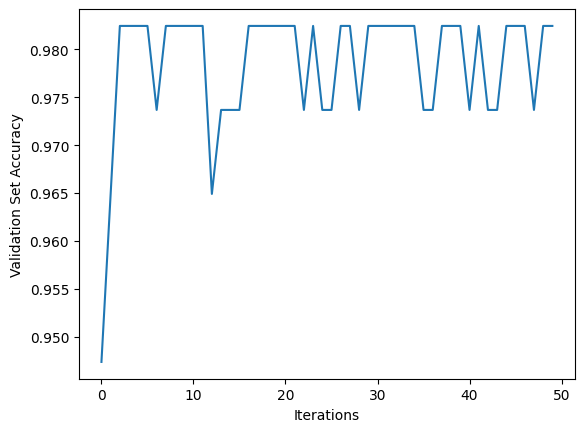

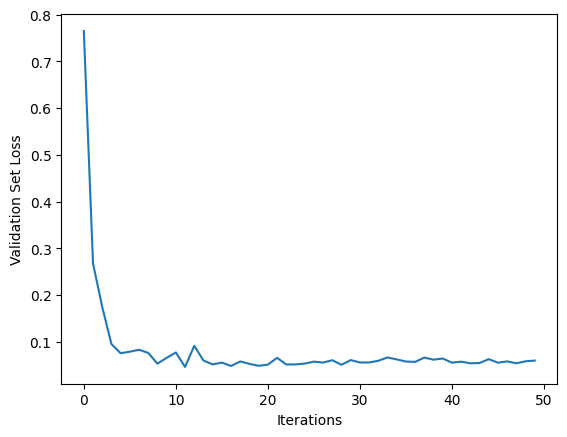

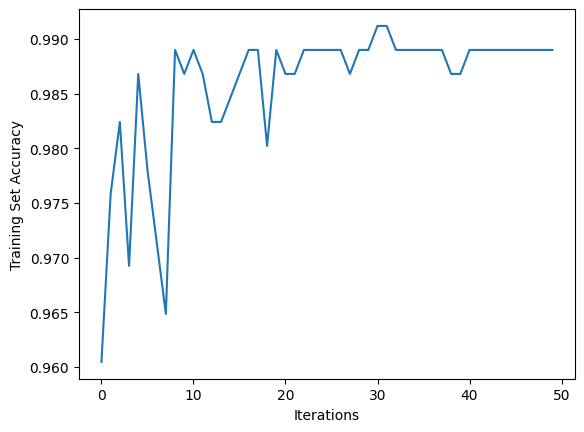

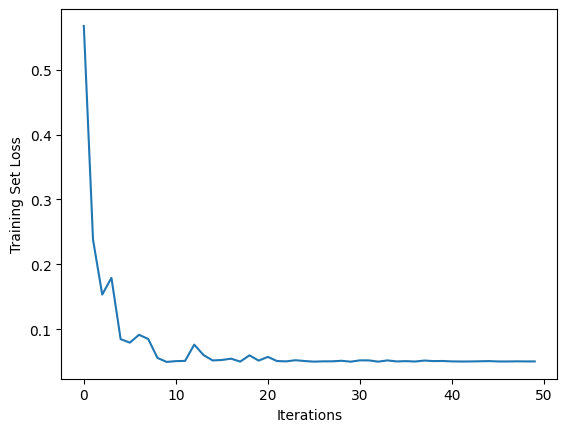

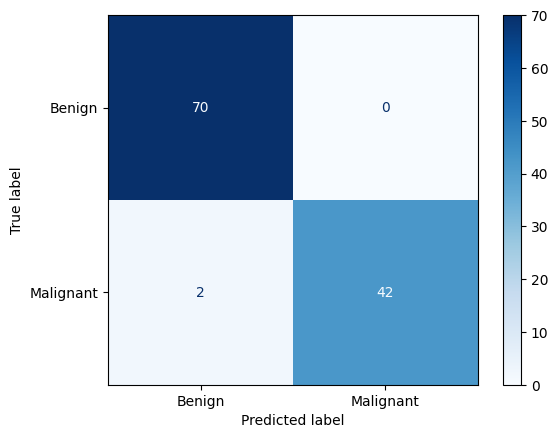

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random as rnd
from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from decimal import Decimal
from sklearn.utils.multiclass import type_of_target
from sklearn.utils.multiclass import type_of_target

filepath = "/content/Cancer.csv"

df = pd.read_csv(filepath)

def getprecision(predict, y):
  p = 0
  tp = 0
  for i in range(len(predict)):
    if predict[i] == 1:
      p += 1
    if predict[i] == 1 and y[i] == 1:
      tp += 1
  return tp/p

def getrecall(predict, y):
  rp = 0
  tp = 0
  for i in range(len(predict)):
    if y[i] == 1:
      rp += 1
    if predict[i] == 1 and y[i] == 1:
      tp += 1
  return tp/rp
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

scaler_X = StandardScaler() # Scaler for input features


y = df.values[:, 1]
for i in range(len(y)):
  if y[i] == "M":
    y[i] = 1
  else:
    y[i] = 0
paramnames = df.columns.values[:]
params = np.zeros(len(df.values[0]))
inputdata = df.values[:, 2:-1]
inputdata, y = shuffle(inputdata, y)

inputdata = np.array(inputdata)
inputdata = scaler_X.fit_transform(inputdata) # Fit and transform input features

validation_indices = np.arange(rnd.randint(0,4), len(inputdata), 5)
validationdata = inputdata[validation_indices]
inputdata = np.delete(inputdata, validation_indices, axis=0)

index = np.arange(0, len(inputdata[0]))

y=y.astype(int)

validationy = y[validation_indices]
y = np.delete(y, validation_indices)

v_accuracy_over_time=[]
v_loss_over_time=[]
t_accuracy_over_time=[]
t_loss_over_time=[]

clf = SGDClassifier(max_iter=1, tol=2e-6, loss='log_loss', alpha = 0.001, warm_start=True)
result = clf.partial_fit(inputdata, y, classes=np.unique(y))

for i in range(50):
  v_accuracy_over_time.append(result.score(validationdata, validationy))
  v_loss_over_time.append(log_loss(validationy, result.predict_proba(validationdata)))
  t_accuracy_over_time.append(result.score(inputdata, y))
  t_loss_over_time.append(log_loss(y, result.predict_proba(inputdata)))
  result = clf.partial_fit(inputdata, y)

precision = getprecision(result.predict(validationdata), validationy)
recall = getrecall(result.predict(validationdata), validationy)
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {getf1(precision, recall)}")

plt.plot(v_accuracy_over_time)
plt.xlabel("Iterations")
plt.ylabel("Validation Set Accuracy")
plt.show()

plt.plot(v_loss_over_time)
plt.xlabel("Iterations")
plt.ylabel("Validation Set Loss")
plt.show()

plt.plot(t_accuracy_over_time)
plt.xlabel("Iterations")
plt.ylabel("Training Set Accuracy")
plt.show()

plt.plot(t_loss_over_time)
plt.xlabel("Iterations")
plt.ylabel("Training Set Loss")
plt.show()

class_names = ["Benign", "Malignant"]

disp = ConfusionMatrixDisplay.from_estimator(
      result,
      validationdata,
      validationy,
      display_labels=class_names,
      cmap=plt.cm.Blues,
      normalize=None,
 )